# Customer Churn Prediction and Retention Analytics

Objective: rank next-cycle churn risk under a 20% contact budget. Observational predictions guide experiments; intervention effects require validation.

Contents: A Audit; B EDA; C Features; D Models; E Evaluation; F Explanations; G Targeting; H Conclusions. The authoritative assignment is DS 01.pdf; all A-H and advanced requirements are implemented below.

## A. Reproducibility, source requirements and independent holdout

In [1]:
%matplotlib inline
from pathlib import Path
import json, sys, platform, subprocess, importlib.metadata as md
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
from IPython.display import display, Markdown, Image
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import *
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from churn_features import CustomerFeatures, NUM, CAT, ENG
SEED=42
CFG={'contact_cost':5,'retained_value':200,'success_rate':0.25,'capacity':0.2}
Path('figures').mkdir(exist_ok=True); Path('results').mkdir(exist_ok=True)
sns.set_theme(style='whitegrid',palette=['#197f86','#d48254'])
raw=pd.read_csv('customer_churn_advanced_dataset.csv')
assert raw.shape==(1200,20) and set(raw.churn)=={0,1} and raw.customer_id.is_unique
train_idx,test_idx=train_test_split(raw.index,test_size=.2,stratify=raw.churn,random_state=SEED)
train=raw.loc[train_idx].copy(); test=raw.loc[test_idx].copy()
X=train.drop(columns=['churn','customer_id']); y=train.churn
Xt=test.drop(columns=['churn','customer_id']); yt=test.churn
assert set(train_idx).isdisjoint(test_idx)
pd.DataFrame({'row':list(train_idx)+list(test_idx),'split':['train']*len(train_idx)+['test']*len(test_idx)}).to_csv('results/split.csv',index=False)
display(Markdown('One stratified 80/20 split is locked before analysis. EDA and all model decisions use the 960 training customers. The 240 test labels are used only after model and threshold selection. Seed: 42.'))
versions={p:md.version(p) for p in ['numpy','pandas','scikit-learn','matplotlib','seaborn','joblib','nbformat','nbclient','reportlab','pypdf','pdfplumber','ipykernel']}
display(versions)
Path('requirements.txt').write_text('\n'.join(f'{p}=={v}' for p,v in versions.items())+'\n')


One stratified 80/20 split is locked before analysis. EDA and all model decisions use the 960 training customers. The 240 test labels are used only after model and threshold selection. Seed: 42.

{'numpy': '2.5.4',
 'pandas': '3.0.6',
 'scikit-learn': '1.9.1',
 'matplotlib': '3.11.2',
 'seaborn': '0.13.2',
 'joblib': '1.6.0',
 'nbformat': '5.11.1',
 'nbclient': '0.11.0',
 'reportlab': '5.0.1',
 'pypdf': '6.21.1',
 'pdfplumber': '0.11.10',
 'ipykernel': '7.4.0'}

198

## A. Audit and documented cleaning decisions

In [2]:
audit=pd.DataFrame({'dtype':raw.dtypes.astype(str),'missing':raw.isna().sum(),'missing_pct':raw.isna().mean()*100,'unique':raw.nunique()})
display(audit); display(raw[NUM].describe().T); display(raw.churn.value_counts().to_frame('count'))
print('Exact duplicates:',raw.duplicated().sum(),'Unique IDs:',raw.customer_id.nunique())
display({c:sorted(raw[c].dropna().unique().tolist()) for c in CAT})
domain={'age':(18,120),'tenure_months':(0,1200),'monthly_charges':(0,np.inf),'total_charges':(0,np.inf),'complaints_last_12m':(0,np.inf),'late_payments_last_12m':(0,np.inf),'satisfaction_score':(1,10),'monthly_usage_gb':(0,np.inf),'discount_pct':(0,100),'senior_citizen':(0,1)}
display(pd.Series({c:int(((raw[c]<lo)|(raw[c]>hi)).sum()) for c,(lo,hi) in domain.items()},name='domain_candidates'))
q1=train[NUM].quantile(.25); q3=train[NUM].quantile(.75); iqr=q3-q1
outliers=((train[NUM]<q1-1.5*iqr)|(train[NUM]>q3+1.5*iqr)).sum()
display(outliers.to_frame('training_IQR_flags'))
billing=train[['customer_id','tenure_months','monthly_charges','total_charges','monthly_usage_gb']].copy()
billing['historical_to_current_ratio']=billing.total_charges/(billing.monthly_charges*billing.tenure_months)
display(billing.nlargest(8,'monthly_charges')); display(billing.nlargest(8,'monthly_usage_gb')); display(billing.sort_values('historical_to_current_ratio').iloc[np.r_[0:5,-5:0]])
audit.to_csv('results/audit.csv'); billing.to_csv('results/billing_investigation.csv',index=False)
raw.to_csv('02_cleaned_dataset.csv',index=False)
display(Markdown('Cleaning decision: retain every row, identity, label, category and missing value. No confirmed invalid domain values or duplicates justify edits. The cleaned export is a validated, canonical CSV copy with unchanged values. Large charges/usage and discrepancies between historical charges and current monthly price times tenure are investigation candidates: discounts, price changes or billing errors cannot be distinguished without invoices. No caps, row deletions or inferred repairs. Missing values are imputed only inside training folds. Observed category vocabularies are reported; no external category dictionary was supplied. Timing of measurements and next-cycle target definition must be verified with the data owner.'))


,dtype,missing,missing_pct,unique
customer_id,str,0,0.0,1200
age,int64,0,0.0,58
tenure_months,int64,0,0.0,72
contract_type,str,0,0.0,3
internet_service,str,0,0.0,3
region,str,0,0.0,9
monthly_charges,float64,30,2.5,1067
total_charges,float64,24,2.0,1176
payment_method,str,0,0.0,4
paperless_billing,str,0,0.0,2


,count,mean,std,min,25%,50%,75%,max
age,1200.0,46.746667,16.666702,18.00,32.0000,47.000,61.0000,75.00
tenure_months,1200.0,36.265833,20.917372,1.00,18.0000,35.000,54.0000,72.00
monthly_charges,1170.0,71.429769,25.823951,20.00,54.4450,71.820,86.9950,235.01
total_charges,1176.0,2568.007194,1807.259488,22.73,1119.2300,2244.460,3752.0275,8853.76
complaints_last_12m,1200.0,0.714167,0.846402,0.00,0.0000,1.000,1.0000,5.00
late_payments_last_12m,1200.0,0.837500,0.886989,0.00,0.0000,1.000,1.0000,4.00
satisfaction_score,1152.0,6.744097,1.784122,1.00,5.6000,6.750,8.0000,10.00
monthly_usage_gb,1164.0,66.925773,39.596157,2.00,41.1750,66.400,89.3250,466.90
discount_pct,1200.0,9.163592,6.608772,0.00,3.5775,8.715,13.6950,32.89
senior_citizen,1200.0,0.171667,0.377248,0.00,0.0000,0.000,0.0000,1.00


,count
churn,
1,1036
0,164


Exact duplicates: 0 Unique IDs: 1200


{'contract_type': ['Month-to-month', 'One year', 'Two year'],
 'internet_service': ['DSL', 'Fiber optic', 'No'],
 'region': ['Central',
  'Eastern',
  'North Central',
  'North Western',
  'Northern',
  'Sabaragamuwa',
  'Southern',
  'Uva',
  'Western'],
 'payment_method': ['Bank transfer',
  'Credit card',
  'Electronic check',
  'Mailed check'],
 'paperless_billing': ['No', 'Yes'],
 'dependents': ['No', 'Yes'],
 'support_plan': ['No', 'Yes'],
 'tech_support': ['No', 'Yes']}

...

,training_IQR_flags
age,0
tenure_months,0
monthly_charges,8
total_charges,11
complaints_last_12m,35
late_payments_last_12m,39
satisfaction_score,9
monthly_usage_gb,4
discount_pct,1
senior_citizen,168


,customer_id,tenure_months,monthly_charges,total_charges,monthly_usage_gb,historical_to_current_ratio
635,CUST100636,10,235.01,567.41,96.0,0.241441
650,CUST100651,6,203.65,439.24,94.3,0.359473
604,CUST100605,10,193.06,473.68,77.0,0.245354
22,CUST100023,70,185.81,4627.17,20.4,0.355753
889,CUST100890,2,140.58,323.28,17.7,1.149808
605,CUST100606,4,139.43,513.33,31.5,0.920408
1172,CUST101173,5,138.42,669.35,104.9,0.967129
978,CUST100979,46,136.90,7192.87,60.1,1.142197


,customer_id,tenure_months,monthly_charges,total_charges,monthly_usage_gb,historical_to_current_ratio
684,CUST100685,45,62.77,2619.35,451.3,0.927318
587,CUST100588,8,57.15,470.07,443.3,1.028150
424,CUST100425,40,48.36,1859.96,353.3,0.961518
282,CUST100283,21,127.82,2941.60,169.8,1.095886
853,CUST100854,69,56.15,4180.72,150.2,1.079076
406,CUST100407,11,72.60,747.80,146.5,0.936389
4,CUST100005,47,62.12,2540.63,144.2,0.870186
1154,CUST101155,23,125.63,3181.67,142.6,1.101118


,customer_id,tenure_months,monthly_charges,total_charges,monthly_usage_gb,historical_to_current_ratio
635,CUST100636,10,235.01,567.41,96.0,0.241441
604,CUST100605,10,193.06,473.68,77.0,0.245354
22,CUST100023,70,185.81,4627.17,20.4,0.355753
650,CUST100651,6,203.65,439.24,94.3,0.359473
1088,CUST101089,68,88.20,5099.32,97.6,0.850227
991,CUST100992,30,86.42,NaN,25.6,NaN
35,CUST100036,25,46.60,NaN,135.0,NaN
1063,CUST101064,38,NaN,3664.89,135.8,NaN
540,CUST100541,32,77.68,NaN,34.0,NaN
255,CUST100256,5,NaN,359.80,32.9,NaN


Cleaning decision: retain every row, identity, label, category and missing value. No confirmed invalid domain values or duplicates justify edits. The cleaned export is a validated, canonical CSV copy with unchanged values. Large charges/usage and discrepancies between historical charges and current monthly price times tenure are investigation candidates: discounts, price changes or billing errors cannot be distinguished without invoices. No caps, row deletions or inferred repairs. Missing values are imputed only inside training folds. Observed category vocabularies are reported; no external category dictionary was supplied. Timing of measurements and next-cycle target definition must be verified with the data owner.

## B. Training-only exploratory analysis and interpretations

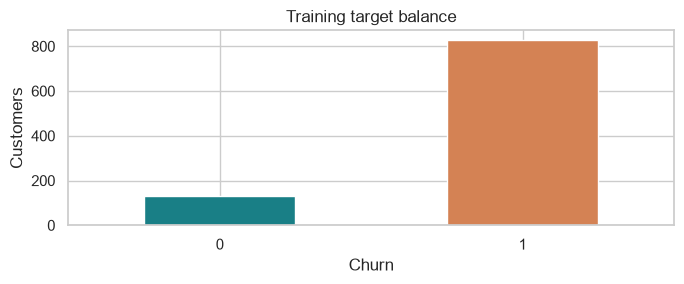

Training churn prevalence is 86.35%. A classifier predicting churn for everyone already achieves this accuracy; random ranking AP is prevalence.

,mean,size
contract_type,,
Month-to-month,0.911032,562
One year,0.800000,245
Two year,0.790850,153


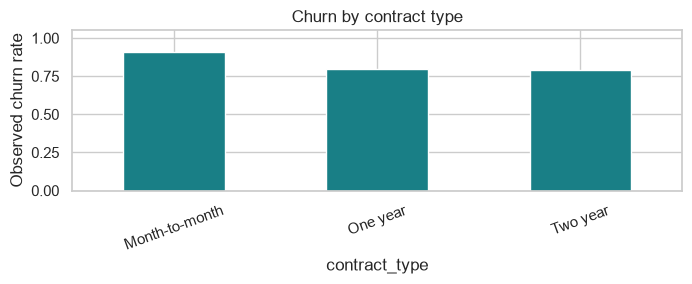

contract_type: highest observed rate Month-to-month (91.1%); lowest Two year (79.1%). Group counts above qualify these descriptive associations; they do not establish intervention effects.

,mean,size
tenure_band,,
0-12,0.874286,175
13-24,0.854651,172
25-48,0.869565,299
49+,0.856688,314


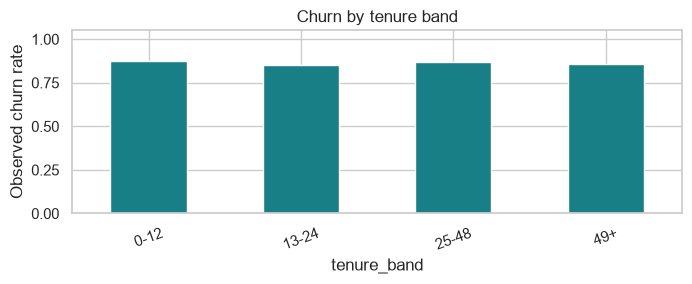

tenure_band: highest observed rate 0-12 (87.4%); lowest 13-24 (85.5%). Group counts above qualify these descriptive associations; they do not establish intervention effects.

,mean,size
payment_method,,
Bank transfer,0.884774,243
Credit card,0.848148,270
Electronic check,0.867925,318
Mailed check,0.844961,129


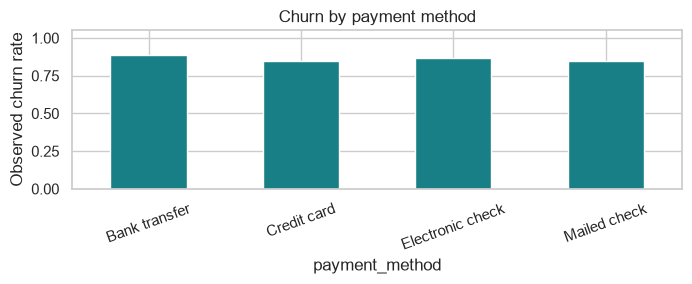

payment_method: highest observed rate Bank transfer (88.5%); lowest Mailed check (84.5%). Group counts above qualify these descriptive associations; they do not establish intervention effects.

,mean,size
internet_service,,
DSL,0.835777,341
Fiber optic,0.895161,496
No,0.813008,123


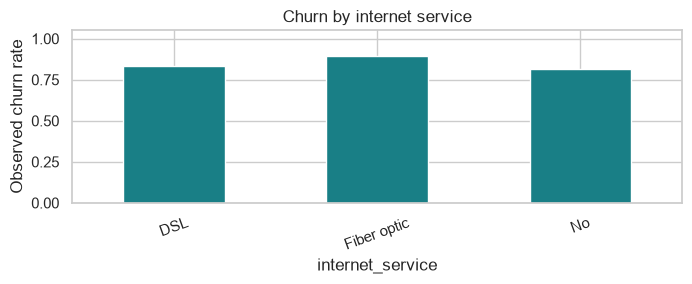

internet_service: highest observed rate Fiber optic (89.5%); lowest No (81.3%). Group counts above qualify these descriptive associations; they do not establish intervention effects.

,mean,size
support_plan,,
No,0.872302,556
Yes,0.851485,404


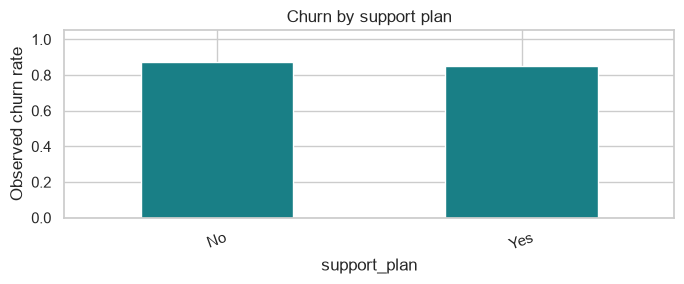

support_plan: highest observed rate No (87.2%); lowest Yes (85.1%). Group counts above qualify these descriptive associations; they do not establish intervention effects.

,mean,size
tech_support,,
No,0.862779,583
Yes,0.864721,377


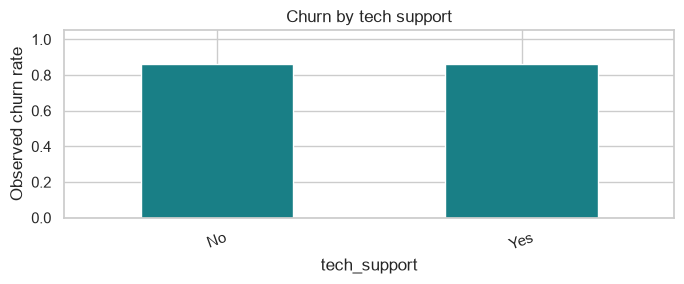

tech_support: highest observed rate Yes (86.5%); lowest No (86.3%). Group counts above qualify these descriptive associations; they do not establish intervention effects.

,mean,size
complaints_last_12m,,
0,0.840671,477
1,0.889881,336
2,0.848214,112
3,1.000000,25
4,0.875000,8
5,1.000000,2


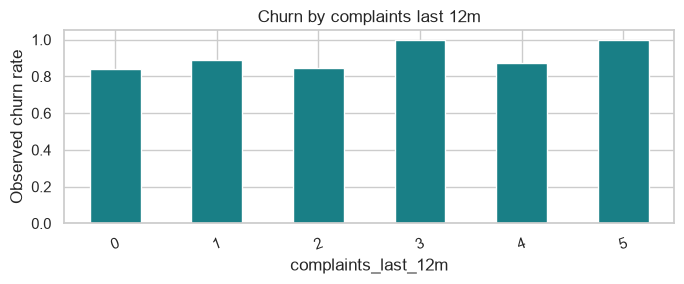

complaints_last_12m: highest observed rate 3 (100.0%); lowest 0 (84.1%). Group counts above qualify these descriptive associations; they do not establish intervention effects.

,mean,size
late_payments_last_12m,,
0,0.847666,407
1,0.856369,369
2,0.917241,145
3,0.896552,29
4,0.900000,10


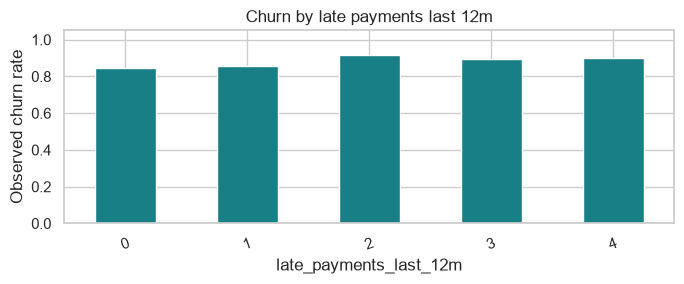

late_payments_last_12m: highest observed rate 2 (91.7%); lowest 0 (84.8%). Group counts above qualify these descriptive associations; they do not establish intervention effects.

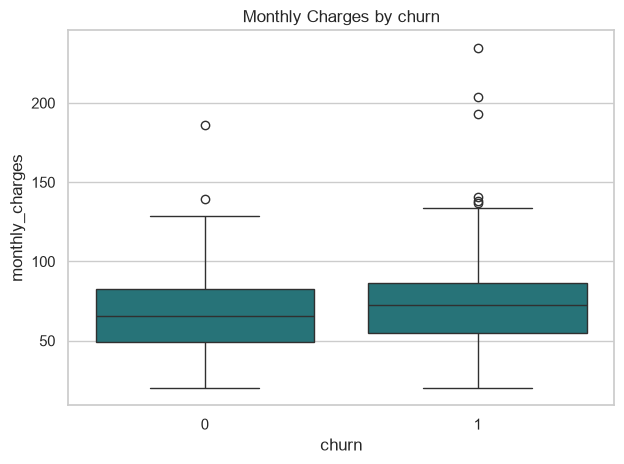

Median monthly_charges: non-churn 65.79, churn 72.27. Overlap and extreme observations limit simple cutoffs; missing observations are omitted in this chart.

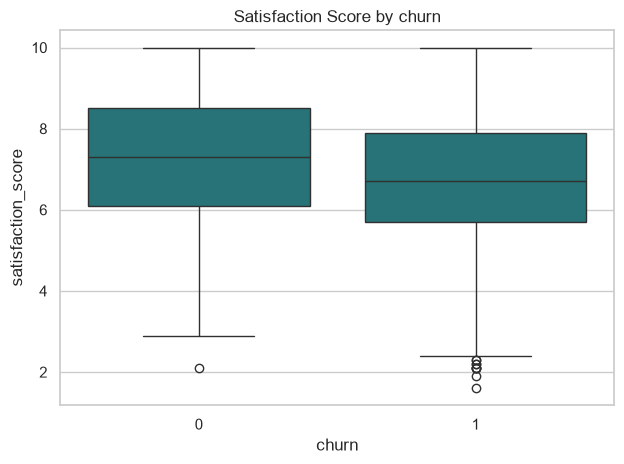

Median satisfaction_score: non-churn 7.30, churn 6.70. Overlap and extreme observations limit simple cutoffs; missing observations are omitted in this chart.

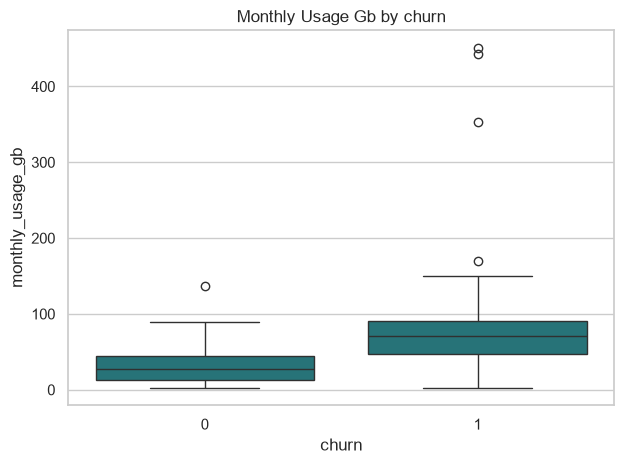

Median monthly_usage_gb: non-churn 28.00, churn 70.75. Overlap and extreme observations limit simple cutoffs; missing observations are omitted in this chart.

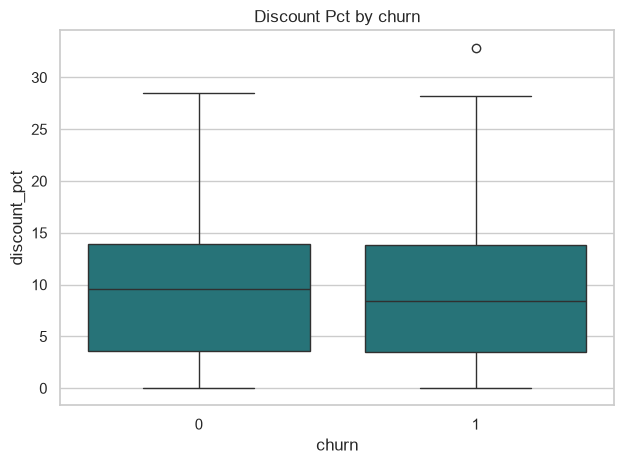

Median discount_pct: non-churn 9.62, churn 8.46. Overlap and extreme observations limit simple cutoffs; missing observations are omitted in this chart.

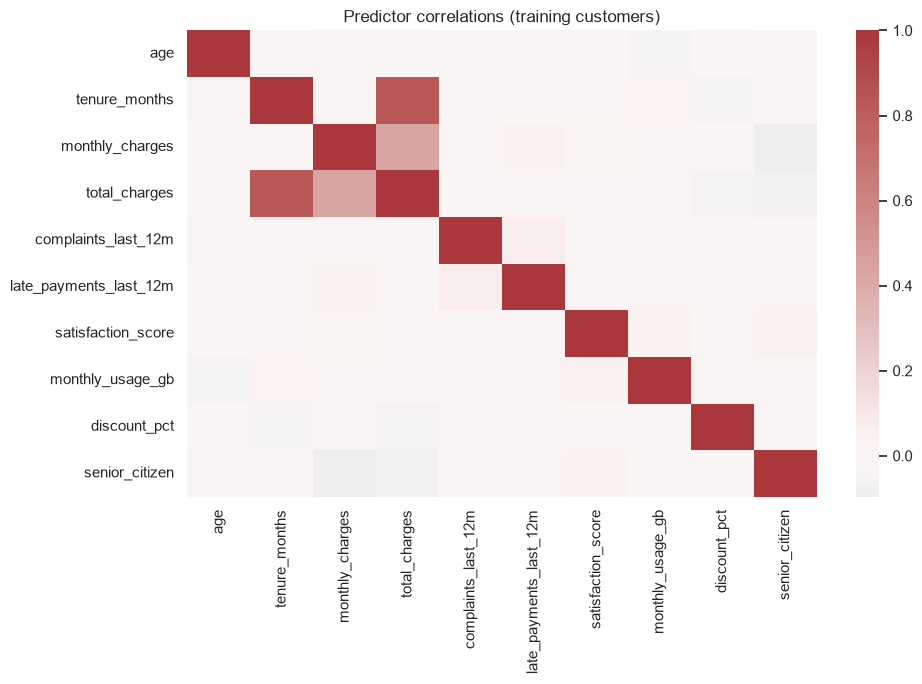

Correlated billing and tenure measures may share information. Marginal correlation does not describe nonlinear predictive relationships or causality.

mean  size
contract_type  low_satisfaction                
Month-to-month False             0.903689   488
               True              0.959459    74
One year       False             0.775120   209
               True              0.944444    36
Two year       False             0.789062   128
               True              0.800000    25

,monthly_charges,total_charges,satisfaction_score,monthly_usage_gb
False,0.862661,0.861702,0.860087,0.864461
True,0.892857,0.950000,0.947368,0.826087


Interaction and missingness tables are exploratory training summaries. Small groups are unstable. Tree models allow nonlinearities; engineered interactions are compared by CV. Missingness may reflect collection practices and must be monitored.

In [3]:
fig_notes=[]
def savefig(name,note):
    plt.tight_layout(); plt.savefig('figures/'+name+'.png',dpi=180,bbox_inches='tight'); plt.show(); plt.close()
    fig_notes.append((name,note)); display(Markdown(note))
counts=train.churn.value_counts().sort_index(); counts.plot.bar(figsize=(7,3),rot=0,color=['#197f86','#d48254']); plt.title('Training target balance'); plt.xlabel('Churn'); plt.ylabel('Customers')
savefig('target',f'Training churn prevalence is {y.mean():.2%}. A classifier predicting churn for everyone already achieves this accuracy; random ranking AP is prevalence.')
eda=train.copy(); eda['tenure_band']=pd.cut(eda.tenure_months,[0,12,24,48,np.inf],labels=['0-12','13-24','25-48','49+'])
for col in ['contract_type','tenure_band','payment_method','internet_service','support_plan','tech_support','complaints_last_12m','late_payments_last_12m']:
    g=eda.groupby(col,observed=True).churn.agg(['mean','size']); display(g)
    g['mean'].plot.bar(figsize=(7,3),rot=20); plt.ylim(0,1.05); plt.ylabel('Observed churn rate'); plt.title('Churn by '+col.replace('_',' '))
    savefig(col,f'{col}: highest observed rate {g["mean"].idxmax()} ({g["mean"].max():.1%}); lowest {g["mean"].idxmin()} ({g["mean"].min():.1%}). Group counts above qualify these descriptive associations; they do not establish intervention effects.')
for col in ['monthly_charges','satisfaction_score','monthly_usage_gb','discount_pct']:
    sns.boxplot(data=eda,x='churn',y=col,showfliers=True); plt.title(col.replace('_',' ').title()+' by churn')
    med=eda.groupby('churn')[col].median()
    savefig(col,f'Median {col}: non-churn {med[0]:.2f}, churn {med[1]:.2f}. Overlap and extreme observations limit simple cutoffs; missing observations are omitted in this chart.')
sns.heatmap(train[NUM].corr(),cmap='vlag',center=0); plt.gcf().set_size_inches(10,7); plt.title('Predictor correlations (training customers)'); savefig('correlation','Correlated billing and tenure measures may share information. Marginal correlation does not describe nonlinear predictive relationships or causality.')
display(train.assign(low_satisfaction=train.satisfaction_score<5).groupby(['contract_type','low_satisfaction']).churn.agg(['mean','size']))
display(pd.DataFrame({c:train.groupby(train[c].isna()).churn.mean() for c in ['monthly_charges','total_charges','satisfaction_score','monthly_usage_gb']}))
display(Markdown('Interaction and missingness tables are exploratory training summaries. Small groups are unstable. Tree models allow nonlinearities; engineered interactions are compared by CV. Missingness may reflect collection practices and must be monitored.'))


## C-D. Serializable features, pipelines, baselines and efficient five-fold tuning

In [4]:
feature_rationale={'tenure_band':'Lifecycle groups, fixed boundaries; available at scoring','charge_per_tenure':'Current price relative to relationship length; denominator >=1','complaint_intensity':'Complaints / min(tenure,12); assumes full observed history','late_payment_intensity':'Late payments / min(tenure,12); same exposure assumption','dissatisfaction_index':'10 - satisfaction, preserving missingness','service_support_gap':'Internet subscription lacking either support service','usage_to_charge_ratio':'Usage / positive monthly charge; otherwise missing','dissatisfaction_complaint_interaction':'Joint dissatisfaction and complaint burden'}
display(feature_rationale)
def pipe(model,eng=True):
    num=NUM+(ENG if eng else []); cat=CAT+(['tenure_band'] if eng else [])
    pre=ColumnTransformer([('numeric',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num),('categorical',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('encode',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),cat)])
    return Pipeline([('features',CustomerFeatures(eng)),('preprocess',pre),('model',model)])
cv=StratifiedKFold(5,shuffle=True,random_state=SEED)
def top_precision(est,x,ytrue):
    p=est.predict_proba(x)[:,1]; k=int(np.ceil(.2*len(p))); return np.asarray(ytrue)[np.argsort(-p,kind='stable')[:k]].mean()
scoring={'ap':'average_precision','roc':'roc_auc','recall':'recall','f1':'f1','top20':top_precision}
candidates={'Logistic':(LogisticRegression(max_iter=2000,random_state=SEED),{'model__C':[.1,1,10],'model__class_weight':[None,'balanced']}),'Forest':(RandomForestClassifier(n_estimators=120,n_jobs=1,random_state=SEED),{'model__max_depth':[4,None],'model__min_samples_leaf':[2,8],'model__class_weight':[None,'balanced']}),'Boosting':(GradientBoostingClassifier(random_state=SEED),{'model__n_estimators':[60,120],'model__learning_rate':[.03,.1],'model__max_depth':[1,2]})}
rows=[]; fitted={}; spaces={}
for name,(model,grid) in {'Dummy':(DummyClassifier(strategy='most_frequent'),{}),**candidates}.items():
    base=pipe(model); scores=cross_validate(base,X,y,cv=cv,scoring=scoring,n_jobs=1)
    rows.append({'model':name,'version':'baseline',**{f'{m}_{s}':float(np.mean(scores['test_'+m]) if s=='mean' else np.std(scores['test_'+m],ddof=1)) for m in scoring for s in ['mean','std']}})
    if grid:
        search=GridSearchCV(base,grid,cv=cv,scoring=scoring,refit='ap',n_jobs=1); search.fit(X,y); fitted[name]=search.best_estimator_; spaces[name]=search.best_params_
        i=search.best_index_; rows.append({'model':name,'version':'tuned',**{f'{m}_{s}':float(search.cv_results_[f'{s}_test_{m}'][i]) for m in scoring for s in ['mean','std']}})
        pd.DataFrame(search.cv_results_).to_csv(f'results/search_{name}.csv',index=False)
comparison=pd.DataFrame(rows); display(comparison); comparison.to_csv('results/model_comparison.csv',index=False); display(spaces)
winner=comparison.query("version=='tuned'").sort_values(['ap_mean','top20_mean'],ascending=False).iloc[0]['model']; final=fitted[winner]
ablation=[]
for eng in [False,True]:
    est=pipe(final.named_steps['model'],eng); s=cross_validate(est,X,y,cv=cv,scoring=scoring)
    ablation.append({'engineered':eng,'ap_mean':np.mean(s['test_ap']),'ap_std':np.std(s['test_ap']),'top20':np.mean(s['test_top20'])})
display(pd.DataFrame(ablation))
use_eng=ablation[1]['ap_mean']>=ablation[0]['ap_mean']; final=pipe(final.named_steps['model'],use_eng)
print('Selected by CV average precision, with top-20 precision as tie break:',winner,'Engineered:',use_eng)
display(Markdown('Five-fold training CV selects AP because ranking drives retention. ROC, recall, F1 and top-20 precision provide context. Class weighting is searched for Logistic and Forest; no resampling is used. CV standard deviations are a robustness check, not confidence intervals. Searching and comparing on the same folds makes winning CV results optimistic; the locked test gives the final independent estimate. All eight features are pre-outcome hypotheses whose timing requires operational validation.'))


{'tenure_band': 'Lifecycle groups, fixed boundaries; available at scoring',
 'charge_per_tenure': 'Current price relative to relationship length; denominator >=1',
 'complaint_intensity': 'Complaints / min(tenure,12); assumes full observed history',
 'late_payment_intensity': 'Late payments / min(tenure,12); same exposure assumption',
 'dissatisfaction_index': '10 - satisfaction, preserving missingness',
 'service_support_gap': 'Internet subscription lacking either support service',
 'usage_to_charge_ratio': 'Usage / positive monthly charge; otherwise missing',
 'dissatisfaction_complaint_interaction': 'Joint dissatisfaction and complaint burden'}

,model,version,ap_mean,ap_std,roc_mean,roc_std,recall_mean,recall_std,f1_mean,f1_std,top20_mean,top20_std
0,Dummy,baseline,0.863542,0.002329,0.500000,0.000000,1.000000,0.000000,0.926773,0.001344,0.871795,0.040542
1,Logistic,baseline,0.969964,0.016538,0.860450,0.053130,0.960219,0.017321,0.930442,0.010451,0.979487,0.021453
2,Logistic,tuned,0.971381,0.014177,0.866961,0.043683,0.979503,0.007212,0.932255,0.002467,0.979487,0.019188
3,Forest,baseline,0.968268,0.009529,0.853731,0.032740,0.987937,0.004260,0.931219,0.005709,0.979487,0.021453
4,Forest,tuned,0.971759,0.009860,0.866844,0.023646,0.835999,0.025425,0.890032,0.011446,0.984615,0.012561
5,Boosting,baseline,0.970160,0.008365,0.866246,0.020008,0.966229,0.005358,0.934658,0.002494,0.984615,0.014044
6,Boosting,tuned,0.977378,0.004987,0.878222,0.017692,0.993976,0.005388,0.928983,0.001737,0.989744,0.012561


{'Logistic': {'model__C': 0.1, 'model__class_weight': None},
 'Forest': {'model__class_weight': 'balanced',
  'model__max_depth': None,
  'model__min_samples_leaf': 8},
 'Boosting': {'model__learning_rate': 0.03,
  'model__max_depth': 1,
  'model__n_estimators': 120}}

,engineered,ap_mean,ap_std,top20
0,False,0.977343,0.005002,0.989744
1,True,0.977378,0.004987,0.989744


Selected by CV average precision, with top-20 precision as tie break: Boosting Engineered: True


Five-fold training CV selects AP because ranking drives retention. ROC, recall, F1 and top-20 precision provide context. Class weighting is searched for Logistic and Forest; no resampling is used. CV standard deviations are a robustness check, not confidence intervals. Searching and comparing on the same folds makes winning CV results optimistic; the locked test gives the final independent estimate. All eight features are pre-outcome hypotheses whose timing requires operational validation.

## E. Training-only threshold choice, then final held-out evaluation

,threshold,precision,recall,f1,utility,fp,fn
0,0.00,0.863542,1.000000,0.926775,36650.0,131,0
10,0.14,0.863542,1.000000,0.926775,36650.0,131,0
20,0.24,0.863542,1.000000,0.926775,36650.0,131,0
30,0.34,0.863542,1.000000,0.926775,36650.0,131,0
40,0.44,0.866109,0.998794,0.927731,36620.0,128,1
50,0.54,0.882609,0.979493,0.928531,36000.0,108,17
60,0.64,0.904872,0.940893,0.922531,34690.0,82,49
70,0.74,0.930905,0.893848,0.912000,33070.0,55,88
80,0.84,0.963801,0.770808,0.856568,28635.0,24,190
90,0.94,0.993007,0.513872,0.677266,19155.0,3,403


Locked training OOF utility threshold: 0.41


{'accuracy': 0.8625,
 'precision': 0.8625,
 'recall': 1.0,
 'f1': 0.9261744966442953,
 'roc_auc': 0.8798126189430536,
 'average_precision': 0.9790757762645282,
 'brier': 0.08995637745452832,
 'test_prevalence': np.float64(0.8625),
 'threshold': 0.41}

              precision    recall  f1-score   support

           0       0.00      0.00      0.00        33
           1       0.86      1.00      0.93       207

    accuracy                           0.86       240
   macro avg       0.43      0.50      0.46       240
weighted avg       0.74      0.86      0.80       240



,pred 0,pred 1
actual 0,0,33
actual 1,0,207


,threshold,precision,recall,flagged
0,0.10,0.862500,1.000000,240
1,0.30,0.862500,1.000000,240
2,0.41,0.862500,1.000000,240
3,0.50,0.866109,1.000000,239
4,0.70,0.909953,0.927536,211
5,0.90,0.973154,0.700483,149
6,0.95,0.990654,0.512077,107


This test threshold sweep is descriptive only; the locked OOF threshold is unchanged. Under the assumed generous benefits, the fixed threshold can flag nearly everyone. The 20% capacity queue remains the operational outreach policy.

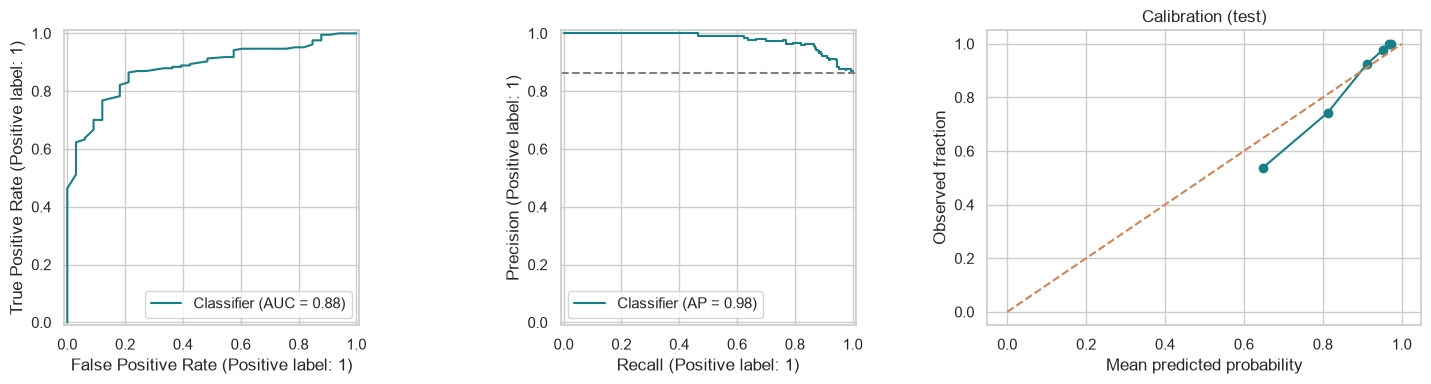

Test curves are descriptive after all decisions are locked. AP must exceed the high prevalence benchmark to add ranking value. Calibration bins contain few non-churners; reliability estimates are uncertain.

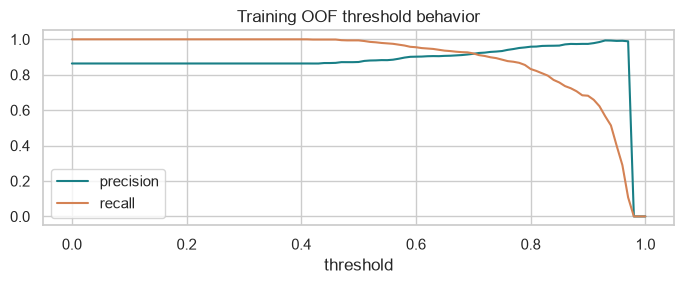

False negatives miss potential retention value; false positives incur contact cost. Utility uses hypothetical homogeneous treatment effects and ignores capacity. The capacity policy is evaluated separately. OOF predictions are conditional on CV-selected hyperparameters and may retain selection optimism.

Constant prevalence Brier benchmark: 0.11859483506944445


In [5]:
oof=cross_val_predict(final,X,y,cv=cv,method='predict_proba')[:,1]
thresholds=np.unique(np.r_[0,np.linspace(.05,.99,95),1])
threshold_rows=[]
for t in thresholds:
    pred=oof>=t; tn,fp,fn,tp=confusion_matrix(y,pred).ravel()
    threshold_rows.append({'threshold':t,'precision':precision_score(y,pred,zero_division=0),'recall':recall_score(y,pred),'f1':f1_score(y,pred),'utility':tp*CFG['success_rate']*CFG['retained_value']-pred.sum()*CFG['contact_cost'],'fp':fp,'fn':fn})
tt=pd.DataFrame(threshold_rows); threshold=float(tt.sort_values(['utility','threshold'],ascending=[False,False]).iloc[0].threshold)
display(tt.iloc[::10]); print('Locked training OOF utility threshold:',threshold)
final.fit(X,y); p=final.predict_proba(Xt)[:,1]; pred=p>=threshold
metrics={'accuracy':accuracy_score(yt,pred),'precision':precision_score(yt,pred,zero_division=0),'recall':recall_score(yt,pred),'f1':f1_score(yt,pred),'roc_auc':roc_auc_score(yt,p),'average_precision':average_precision_score(yt,p),'brier':brier_score_loss(yt,p),'test_prevalence':yt.mean(),'threshold':threshold}
display(metrics); print(classification_report(yt,pred,zero_division=0)); display(pd.DataFrame(confusion_matrix(yt,pred),index=['actual 0','actual 1'],columns=['pred 0','pred 1']))
test_threshold_table=pd.DataFrame([{'threshold':float(t),'precision':precision_score(yt,p>=t,zero_division=0),'recall':recall_score(yt,p>=t),'flagged':int((p>=t).sum())} for t in sorted(set([.1,.3,.5,.7,.9,.95,threshold]))])
display(test_threshold_table); test_threshold_table.to_csv('results/test_thresholds_descriptive.csv',index=False)
display(Markdown('This test threshold sweep is descriptive only; the locked OOF threshold is unchanged. Under the assumed generous benefits, the fixed threshold can flag nearly everyone. The 20% capacity queue remains the operational outreach policy.'))
fig,ax=plt.subplots(1,3,figsize=(15,4)); RocCurveDisplay.from_predictions(yt,p,ax=ax[0]); PrecisionRecallDisplay.from_predictions(yt,p,ax=ax[1]); ax[1].axhline(yt.mean(),ls='--',color='gray'); frac,mp=calibration_curve(yt,p,n_bins=6,strategy='quantile'); ax[2].plot(mp,frac,'o-'); ax[2].plot([0,1],[0,1],'--'); ax[2].set(title='Calibration (test)',xlabel='Mean predicted probability',ylabel='Observed fraction'); savefig('evaluation','Test curves are descriptive after all decisions are locked. AP must exceed the high prevalence benchmark to add ranking value. Calibration bins contain few non-churners; reliability estimates are uncertain.')
tt.plot(x='threshold',y=['precision','recall'],figsize=(7,3)); plt.title('Training OOF threshold behavior'); savefig('thresholds','False negatives miss potential retention value; false positives incur contact cost. Utility uses hypothetical homogeneous treatment effects and ignores capacity. The capacity policy is evaluated separately. OOF predictions are conditional on CV-selected hyperparameters and may retain selection optimism.')
print('Constant prevalence Brier benchmark:',brier_score_loss(yt,np.repeat(y.mean(),len(yt))))
joblib.dump(final,'03_model_artifact.joblib')
pd.DataFrame({'customer_id':test.customer_id,'actual':yt,'probability':p}).to_csv('results/test_predictions.csv',index=False)


## F. Global permutation and three real local risk explanations

The strongest held-out ranking signal is monthly_usage_gb, with AP loss 0.089 when permuted. Weak importance for other inputs means their subgroup associations should not automatically become targeting rules.

,feature,AP_drop,std
15,monthly_usage_gb,0.089370,0.009910
2,contract_type,0.005178,0.002230
14,satisfaction_score,0.000889,0.000530
5,monthly_charges,0.000065,0.000315
1,tenure_months,0.000000,0.000000
0,age,0.000000,0.000000
7,payment_method,0.000000,0.000000
8,paperless_billing,0.000000,0.000000
3,internet_service,0.000000,0.000000
4,region,0.000000,0.000000


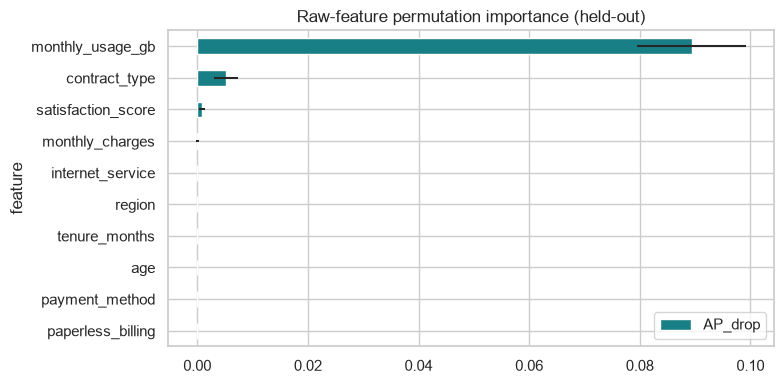

Permuting raw columns aggregates categorical levels and propagates through engineered features. Correlated predictors can mask importance; test importances are explanatory and never fed back into selection.

{'profile': 'low',
 'customer_id': 'CUST100626',
 'probability': 0.45564661182962946,
 'reference_replacement_deltas': [('monthly_usage_gb', -0.40618729471533926),
  ('contract_type', -0.1287136095784271),
  ('satisfaction_score', -0.057267688310295994),
  ('monthly_charges', 0.004500978420118873)],
 'raw_record': {'age': 31,
  'tenure_months': 65,
  'contract_type': 'One year',
  'internet_service': 'DSL',
  'region': 'Uva',
  'monthly_charges': 96.37,
  'total_charges': 6518.92,
  'payment_method': 'Credit card',
  'paperless_billing': 'No',
  'dependents': 'No',
  'support_plan': 'Yes',
  'tech_support': 'Yes',
  'complaints_last_12m': 1,
  'late_payments_last_12m': 0,
  'satisfaction_score': 8.6,
  'monthly_usage_gb': 8.5,
  'discount_pct': 8.58,
  'senior_citizen': 0}}

{'profile': 'medium',
 'customer_id': 'CUST100019',
 'probability': 0.9433945906268654,
 'reference_replacement_deltas': [('monthly_usage_gb', 0.08373757132398651),
  ('contract_type', -0.022114503773907557),
  ('satisfaction_score', -0.011081715652390356),
  ('age', 0.0)],
 'raw_record': {'age': 66,
  'tenure_months': 59,
  'contract_type': 'One year',
  'internet_service': 'Fiber optic',
  'region': 'North Western',
  'monthly_charges': 52.79,
  'total_charges': 3195.43,
  'payment_method': 'Mailed check',
  'paperless_billing': 'Yes',
  'dependents': 'No',
  'support_plan': 'Yes',
  'tech_support': 'No',
  'complaints_last_12m': 1,
  'late_payments_last_12m': 0,
  'satisfaction_score': 10.0,
  'monthly_usage_gb': 91.3,
  'discount_pct': 6.92,
  'senior_citizen': 0}}

{'profile': 'high',
 'customer_id': 'CUST100178',
 'probability': 0.9746243586730003,
 'reference_replacement_deltas': [('monthly_usage_gb', 0.04077833708428025),
  ('satisfaction_score', 0.0017527453300547613),
  ('monthly_charges', 0.00045306612987516814),
  ('age', 0.0)],
 'raw_record': {'age': 27,
  'tenure_months': 55,
  'contract_type': 'Month-to-month',
  'internet_service': 'Fiber optic',
  'region': 'Uva',
  'monthly_charges': 82.27,
  'total_charges': 5058.33,
  'payment_method': 'Electronic check',
  'paperless_billing': 'No',
  'dependents': 'Yes',
  'support_plan': 'No',
  'tech_support': 'Yes',
  'complaints_last_12m': 1,
  'late_payments_last_12m': 3,
  'satisfaction_score': 4.9,
  'monthly_usage_gb': 87.2,
  'discount_pct': 8.93,
  'senior_citizen': 1}}

Local explanations replace one raw attribute with its training median/mode and recompute risk, including dependent engineered features. Deltas measure model sensitivity relative to that reference, are not additive attribution, may create implausible combinations, and are not causal effects. Medium means median predicted rank in this high-prevalence cohort.

In [6]:
imp=permutation_importance(final,Xt,yt,scoring='average_precision',n_repeats=8,random_state=SEED,n_jobs=1)
importance=pd.DataFrame({'feature':Xt.columns,'AP_drop':imp.importances_mean,'std':imp.importances_std}).sort_values('AP_drop',ascending=False)
display(Markdown(f'The strongest held-out ranking signal is {importance.iloc[0].feature}, with AP loss {importance.iloc[0].AP_drop:.3f} when permuted. Weak importance for other inputs means their subgroup associations should not automatically become targeting rules.'))
display(importance); importance.to_csv('results/importance.csv',index=False)
importance.head(10).sort_values('AP_drop').plot.barh(x='feature',y='AP_drop',xerr='std',figsize=(8,4)); plt.title('Raw-feature permutation importance (held-out)'); savefig('importance','Permuting raw columns aggregates categorical levels and propagates through engineered features. Correlated predictors can mask importance; test importances are explanatory and never fed back into selection.')
local=[]
for profile,pos in [('low',np.argmin(p)),('medium',np.argsort(p)[len(p)//2]),('high',np.argmax(p))]:
    row=Xt.iloc[[pos]].copy(); effects=[]
    for col in Xt.columns:
        changed=row.copy(); changed[col]=X[col].median() if col in NUM else X[col].mode().iloc[0]
        effects.append((col,float(p[pos]-final.predict_proba(changed)[:,1][0])))
    effects=sorted(effects,key=lambda z:abs(z[1]),reverse=True)[:4]
    item={'profile':profile,'customer_id':test.iloc[pos].customer_id,'probability':float(p[pos]),'reference_replacement_deltas':effects,'raw_record':row.iloc[0].to_dict()}; local.append(item); display(item)
display(Markdown('Local explanations replace one raw attribute with its training median/mode and recompute risk, including dependent engineered features. Deltas measure model sensitivity relative to that reference, are not additive attribution, may create implausible combinations, and are not causal effects. Medium means median predicted rank in this high-prevalence cohort.'))


## G. Exact capacity targeting and hypothetical economics

{'contacted': 48,
 'true_churners_reached': 48,
 'precision_at_20': 1.0,
 'recall_at_20': np.float64(0.2318840579710145),
 'lift': np.float64(1.1594202898550725),
 'random_expected_churners': np.float64(41.400000000000006),
 'expected_retained': 12.0,
 'cost': 240,
 'gross_value': 2400.0,
 'net_benefit': 2160.0,
 'incremental_net_vs_random': np.float64(329.9999999999997)}

,success_rate,retained_value,model_net,random_net,incremental
0,0.10,100,240.0,174.0,66.0
1,0.10,200,720.0,588.0,132.0
2,0.10,400,1680.0,1416.0,264.0
3,0.25,100,960.0,795.0,165.0
4,0.25,200,2160.0,1830.0,330.0
5,0.25,400,4560.0,3900.0,660.0
6,0.40,100,1680.0,1416.0,264.0
7,0.40,200,3600.0,3072.0,528.0
8,0.40,400,7440.0,6384.0,1056.0


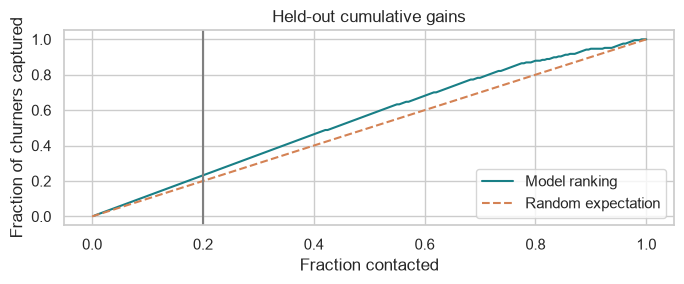

Uniform random contact has expected precision equal to held-out prevalence and expected recall equal to contact fraction. Deterministic ties use customer ID only after prediction. The model cannot contact more than 48 test customers.

Random capture 2.5/50/97.5 percentiles: [37. 41. 45.]


These are out-of-sample targeting diagnostics and hypothetical deployment economics, not observed retention outcomes. Success rates, homogeneous value and treatment effects are assumed. Random selection uncertainty, customer consent, operational costs and effect heterogeneity can materially change value. Run a randomized retention trial before claiming ROI.

In [7]:
ranked=pd.DataFrame({'customer_id':test.customer_id.to_numpy(),'actual':yt.to_numpy(),'probability':p}).sort_values(['probability','customer_id'],ascending=[False,True])
k=int(np.ceil(CFG['capacity']*len(test))); reached=int(ranked.head(k).actual.sum()); random_reached=k*yt.mean()
target={'contacted':k,'true_churners_reached':reached,'precision_at_20':reached/k,'recall_at_20':reached/yt.sum(),'lift':(reached/k)/yt.mean(),'random_expected_churners':random_reached,'expected_retained':reached*CFG['success_rate'],'cost':k*CFG['contact_cost'],'gross_value':reached*CFG['success_rate']*CFG['retained_value'],'net_benefit':reached*CFG['success_rate']*CFG['retained_value']-k*CFG['contact_cost'],'incremental_net_vs_random':(reached-random_reached)*CFG['success_rate']*CFG['retained_value']}
display(target); ranked.assign(contact=np.arange(len(ranked))<k).to_csv('results/targeting.csv',index=False)
sensitivity=pd.DataFrame([{'success_rate':s,'retained_value':v,'model_net':reached*s*v-k*CFG['contact_cost'],'random_net':random_reached*s*v-k*CFG['contact_cost'],'incremental':(reached-random_reached)*s*v} for s in [.1,.25,.4] for v in [100,200,400]])
display(sensitivity); sensitivity.to_csv('results/sensitivity.csv',index=False)
plt.figure(figsize=(7,3)); plt.plot(np.arange(1,len(test)+1)/len(test),ranked.actual.cumsum()/yt.sum(),label='Model ranking'); plt.plot([0,1],[0,1],'--',label='Random expectation'); plt.axvline(.2,color='gray'); plt.xlabel('Fraction contacted'); plt.ylabel('Fraction of churners captured'); plt.title('Held-out cumulative gains'); plt.legend(); savefig('gains','Uniform random contact has expected precision equal to held-out prevalence and expected recall equal to contact fraction. Deterministic ties use customer ID only after prediction. The model cannot contact more than 48 test customers.')
rng=np.random.default_rng(SEED); random_captures=np.array([rng.choice(yt.to_numpy(),k,replace=False).sum() for _ in range(2000)])
print('Random capture 2.5/50/97.5 percentiles:',np.quantile(random_captures,[.025,.5,.975]))
display(Markdown('These are out-of-sample targeting diagnostics and hypothetical deployment economics, not observed retention outcomes. Success rates, homogeneous value and treatment effects are assumed. Random selection uncertainty, customer consent, operational costs and effect heterogeneity can materially change value. Run a randomized retention trial before claiming ROI.'))


## H. Business conclusions, report generation and reproducibility

In [8]:
recommendations=[f'Pilot the top-risk queue: contact {k} of {len(test)} comparable customers; measured capture is {reached} churners versus {random_reached:.1f} expected randomly.', 'Use the contract-rate evidence to test renewal reminders and contract-fit conversations; measure incremental retention by randomized assignment.', 'Use satisfaction and complaint evidence to triage service recovery; test response quality and timing rather than assuming a causal benefit.', 'Use late-payment and payment-method evidence to test opt-in billing assistance; avoid punitive targeting or sensitive financial profiling.', 'Use support and usage evidence to test relevant support onboarding and plan-fit reviews. Audit subgroup access and outcomes, including age and region.']
display(Markdown('\n\n'.join(recommendations)))
display(Markdown('Limitations: only 1,200 records, no timestamps, uncertain sampling/target provenance and feature timing, unusual churn prevalence, only 33 non-churners in the test set, one random split and no temporal/external validation. Protected/proxy variables require fairness review. Predictions can drift; monitor missingness, calibration, outreach burden and incremental effects. The selected model follows CV AP, with feature ablation on training folds; test outcomes are reported once.'))
summary={'winner':winner,'engineered':bool(use_eng),'metrics':{a:float(b) for a,b in metrics.items()},'targeting':{a:float(b) for a,b in target.items()},'config':CFG,'local':local,'recommendations':recommendations,'versions':versions}
Path('results/summary.json').write_text(json.dumps(summary,indent=2,default=str))
from report import create_report
create_report(summary,comparison,audit,fig_notes,importance,sensitivity)
print('Report and model saved. Full submission checks run after notebook execution.')


Pilot the top-risk queue: contact 48 of 240 comparable customers; measured capture is 48 churners versus 41.4 expected randomly.

Use the contract-rate evidence to test renewal reminders and contract-fit conversations; measure incremental retention by randomized assignment.

Use satisfaction and complaint evidence to triage service recovery; test response quality and timing rather than assuming a causal benefit.

Use late-payment and payment-method evidence to test opt-in billing assistance; avoid punitive targeting or sensitive financial profiling.

Use support and usage evidence to test relevant support onboarding and plan-fit reviews. Audit subgroup access and outcomes, including age and region.

Limitations: only 1,200 records, no timestamps, uncertain sampling/target provenance and feature timing, unusual churn prevalence, only 33 non-churners in the test set, one random split and no temporal/external validation. Protected/proxy variables require fairness review. Predictions can drift; monitor missingness, calibration, outreach burden and incremental effects. The selected model follows CV AP, with feature ablation on training folds; test outcomes are reported once.

Report and model saved. Full submission checks run after notebook execution.
